In [1]:
import os
import sys
import glob
import time
import hashlib
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
import joblib
import json

try:
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings('ignore')
plt.style.use('default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 10
sns.set_theme(style='whitegrid', palette='muted')

def resolve_dataset_path(candidate_paths, description):
    for candidate in candidate_paths:
        if os.path.exists(candidate):
            return os.path.abspath(candidate)
    searched_list = "\n  * ".join(candidate_paths)
    err_message = f"\nUnable to locate: {description}\nSearched:\n  * {searched_list}\n"
    raise FileNotFoundError(err_message)

FERTILIZER_CANDIDATES = [
    "Fertilizer Recommendation System/Fertilizer_Recommendation_dataset.csv",
    "Fertilizer_Recommendation_dataset.csv",
    "../Fertilizer Recommendation System/Fertilizer_Recommendation_dataset.csv",
    "./AIML/Fertilizer Recommendation System/Fertilizer_Recommendation_dataset.csv",
    "AIML/Fertilizer Recommendation System/Fertilizer_Recommendation_dataset.csv"
]
FERTILIZER_DATA_PATH = resolve_dataset_path(FERTILIZER_CANDIDATES, "Fertilizer Recommendation CSV")

CROP_CANDIDATES = [
    "Crop Recommendation Dataset/Crop_Recommendation_dataset.csv",
    "Crop_Recommendation_dataset.csv",
    "../Crop Recommendation Dataset/Crop_Recommendation_dataset.csv",
    "./AIML/Crop Recommendation Dataset/Crop_Recommendation_dataset.csv",
    "AIML/Crop Recommendation Dataset/Crop_Recommendation_dataset.csv"
]
CROP_DATA_PATH = resolve_dataset_path(CROP_CANDIDATES, "Crop Recommendation CSV")

BASE_DIR = os.path.dirname(FERTILIZER_DATA_PATH)
if os.path.basename(BASE_DIR) in ["Fertilizer Recommendation System", "Crop Recommendation Dataset"]:
    BASE_DIR = os.path.dirname(BASE_DIR)

ML_OUTPUT_DIR = os.path.join(BASE_DIR, "preprocessed_output", "ML")
FERT_DIR = os.path.join(ML_OUTPUT_DIR, "fertilizer")
CROP_DIR = os.path.join(ML_OUTPUT_DIR, "crop")
REPORT_DIR = os.path.join(ML_OUTPUT_DIR, "reports")

for d in [FERT_DIR, CROP_DIR, REPORT_DIR]:
    os.makedirs(d, exist_ok=True)

print("Machine Learning Environment & Directories Initialized Successfully")
print("Base Path:", BASE_DIR)
print("Fertilizer Dataset Path:", FERTILIZER_DATA_PATH)
print("Crop Dataset Path:", CROP_DATA_PATH)
print("ML Output Directory:", ML_OUTPUT_DIR)


Machine Learning Environment & Directories Initialized Successfully
Base Path: C:\Users\khanp\Downloads\infosy virtual intership 7.0\AIML
Fertilizer Dataset Path: C:\Users\khanp\Downloads\infosy virtual intership 7.0\AIML\Fertilizer Recommendation System\Fertilizer_Recommendation_dataset.csv
Crop Dataset Path: C:\Users\khanp\Downloads\infosy virtual intership 7.0\AIML\Crop Recommendation Dataset\Crop_Recommendation_dataset.csv
ML Output Directory: C:\Users\khanp\Downloads\infosy virtual intership 7.0\AIML\preprocessed_output\ML


In [2]:
def dynamic_column_classifier(df, target_hints=['fertilizer', 'crop', 'label', 'recommendation', 'target']):
    numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    categorical_cols = df.select_dtypes(include=['object', 'category', 'string']).columns.tolist()
    target_candidate = None
    for hint in target_hints:
        matches = [c for c in categorical_cols if hint.lower() in c.lower()]
        if matches:
            target_candidate = matches[0]
            break
    feature_cols = [c for c in df.columns if c != target_candidate]
    return {
        'numerical': numerical_cols,
        'categorical': categorical_cols,
        'target': target_candidate,
        'features': feature_cols
    }

def compute_iqr_outliers(df, num_cols):
    summary = []
    indices_dict = {}
    for col in num_cols:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        lower_fence = q1 - 1.5 * iqr
        upper_fence = q3 + 1.5 * iqr
        mask = (df[col] < lower_fence) | (df[col] > upper_fence)
        count = mask.sum()
        pct = (count / len(df)) * 100
        indices_dict[col] = df[mask].index.tolist()
        summary.append({
            'Feature': col,
            'Q1 (25th)': round(q1, 3),
            'Median (50th)': round(df[col].median(), 3),
            'Q3 (75th)': round(q3, 3),
            'IQR': round(iqr, 3),
            'Lower Fence': round(lower_fence, 3),
            'Upper Fence': round(upper_fence, 3),
            'Outlier Count': count,
            'Outlier Percentage (%)': round(pct, 2)
        })
    return pd.DataFrame(summary), indices_dict

def compute_skewness_kurtosis(df, num_cols):
    records = []
    for col in num_cols:
        s = df[col].dropna()
        records.append({
            'Feature': col,
            'Skewness': round(float(s.skew()), 4),
            'Kurtosis': round(float(s.kurtosis()), 4),
            'Distribution Shape': 'Approximately Symmetric' if abs(s.skew()) < 0.5 else ('Moderately Skewed' if abs(s.skew()) < 1.0 else 'Highly Skewed')
        })
    return pd.DataFrame(records)


In [3]:
fertilizer_raw_df = pd.read_csv(FERTILIZER_DATA_PATH)
print("Fertilizer Dataset Shape:", fertilizer_raw_df.shape)
display(fertilizer_raw_df.head(5))
display(fertilizer_raw_df.tail(5))
fertilizer_raw_df.info()
display(fertilizer_raw_df.describe().T)
display(fertilizer_raw_df.describe(include=['object', 'category']).T)

fert_col_meta = dynamic_column_classifier(fertilizer_raw_df, target_hints=['fertilizer'])
print("Numerical Features:", fert_col_meta['numerical'])
print("Categorical Features:", fert_col_meta['categorical'])
print("Target Column:", fert_col_meta['target'])

fert_null_counts = fertilizer_raw_df.isnull().sum()
fert_null_pct = (fert_null_counts / len(fertilizer_raw_df)) * 100
fert_missing_report = pd.DataFrame({
    'Column': fertilizer_raw_df.columns,
    'Data Type': fertilizer_raw_df.dtypes.values,
    'Missing Count': fert_null_counts.values,
    'Missing (%)': fert_null_pct.round(4).values
}).sort_values(by='Missing Count', ascending=False)
display(fert_missing_report)

fert_duplicate_count = fertilizer_raw_df.duplicated().sum()
print("Exact Duplicate Records:", fert_duplicate_count)

fert_cat_audit = []
for col in fert_col_meta['categorical']:
    series = fertilizer_raw_df[col].dropna().astype(str)
    has_ws = (series != series.str.strip()).any()
    unique_count = series.nunique()
    samples = series.unique()[:6].tolist()
    fert_cat_audit.append({
        'Feature': col,
        'Has Whitespace Inconsistencies': has_ws,
        'Unique Class Count': unique_count,
        'Sample Classes': samples
    })
display(pd.DataFrame(fert_cat_audit))

fert_outlier_df, fert_outlier_indices = compute_iqr_outliers(fertilizer_raw_df, fert_col_meta['numerical'])
display(fert_outlier_df)

fert_skew_df = compute_skewness_kurtosis(fertilizer_raw_df, fert_col_meta['numerical'])
display(fert_skew_df)


Fertilizer Dataset Shape: (10000, 9)
  soil_type   crop_type crop_growth_stage  ... phosphorus  potassium  fertilizer
0      Arid        rice      Sowing/Basal  ...         77         26         MOP
1    Yellow  watermelon      Sowing/Basal  ...          8         69         DAP
2      Arid      lentil      Sowing/Basal  ...         66         59        Urea
3       Red        rice        Vegetative  ...          5         42         DAP
4  Alluvial      tomato      Sowing/Basal  ...         12         42         DAP

[5 rows x 9 columns]
     soil_type  crop_type crop_growth_stage  ... phosphorus  potassium  fertilizer
9995      Arid  blackgram      Sowing/Basal  ...         25         64         DAP
9996  Laterite   chickpea      Sowing/Basal  ...         29         83         DAP
9997     Black     grapes        Vegetative  ...          9         57         DAP
9998  Mountain     coffee        Vegetative  ...         58         47        Urea
9999    Yellow     cotton         Flower

             Metric  Raw Dataset  Cleaned Dataset
0     Total Records        10000            10000
1     Total Columns            9                9
2    Missing Values            0                0
3  Exact Duplicates            0                0
4    Target Classes            7                7


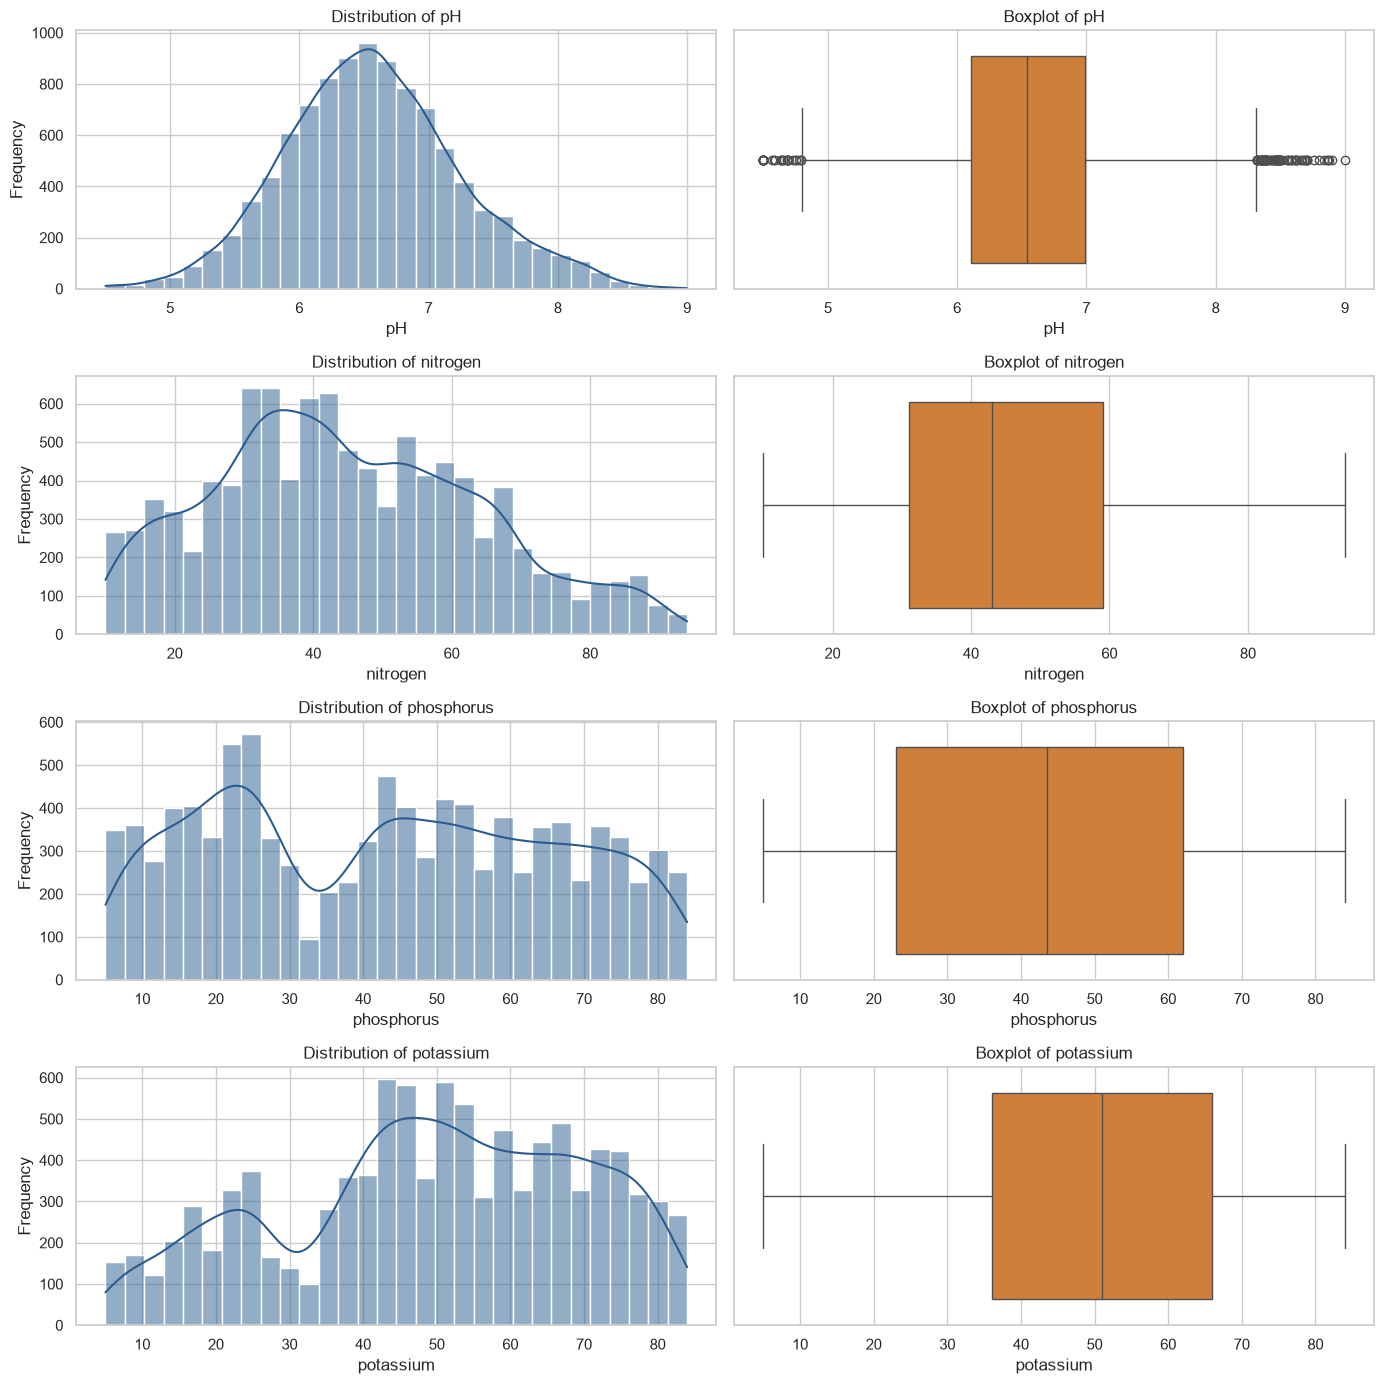

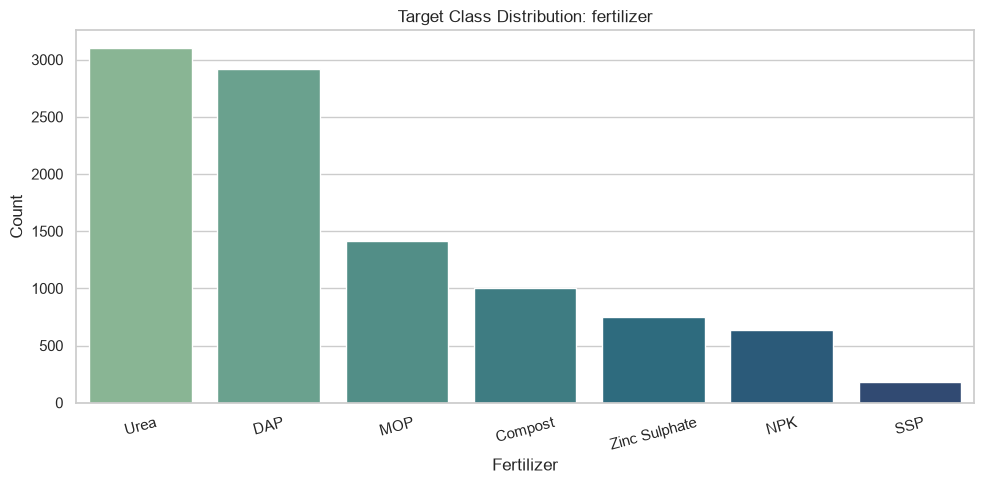

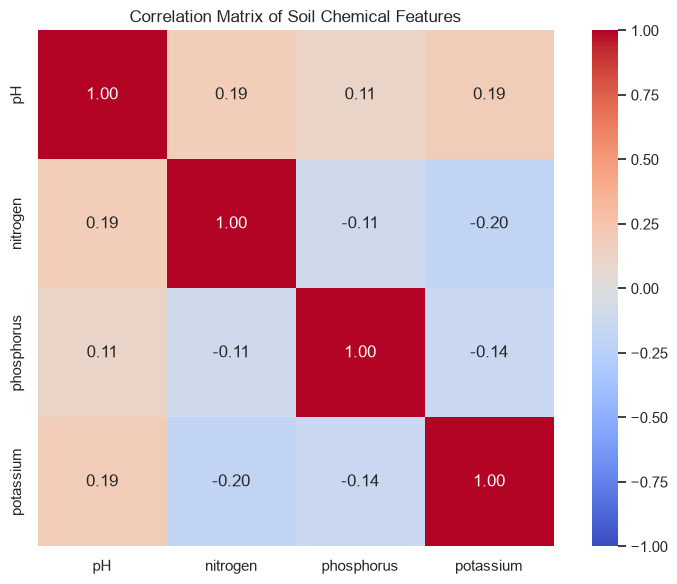

In [4]:
fig, axes = plt.subplots(nrows=len(fert_col_meta['numerical']), ncols=2, figsize=(14, 3.5 * len(fert_col_meta['numerical'])))
for idx, col in enumerate(fert_col_meta['numerical']):
    sns.histplot(fertilizer_raw_df[col], kde=True, ax=axes[idx, 0], color='#2b5c8f', bins=30)
    axes[idx, 0].set_title(f"Distribution of {col}")
    axes[idx, 0].set_xlabel(col)
    axes[idx, 0].set_ylabel("Frequency")
    sns.boxplot(x=fertilizer_raw_df[col], ax=axes[idx, 1], color='#e67e22')
    axes[idx, 1].set_title(f"Boxplot of {col}")
    axes[idx, 1].set_xlabel(col)
plt.tight_layout()
plt.show()

if fert_col_meta['target']:
    plt.figure(figsize=(10, 5))
    target_counts = fertilizer_raw_df[fert_col_meta['target']].value_counts()
    ax = sns.barplot(x=target_counts.index, y=target_counts.values, palette='crest')
    plt.title(f"Target Class Distribution: {fert_col_meta['target']}")
    plt.xlabel("Fertilizer")
    plt.ylabel("Count")
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(fertilizer_raw_df[fert_col_meta['numerical']].corr(), annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1, square=True)
plt.title("Correlation Matrix of Soil Chemical Features")
plt.tight_layout()
plt.show()

fertilizer_cleaned_df = fertilizer_raw_df.copy()
for col in fert_col_meta['categorical']:
    fertilizer_cleaned_df[col] = fertilizer_cleaned_df[col].astype(str).str.strip()
fertilizer_cleaned_df = fertilizer_cleaned_df.drop_duplicates().reset_index(drop=True)

validation_comparison = pd.DataFrame({
    'Metric': ['Total Records', 'Total Columns', 'Missing Values', 'Exact Duplicates', 'Target Classes'],
    'Raw Dataset': [
        len(fertilizer_raw_df), 
        fertilizer_raw_df.shape[1], 
        fertilizer_raw_df.isnull().sum().sum(), 
        fert_duplicate_count,
        fertilizer_raw_df[fert_col_meta['target']].nunique() if fert_col_meta['target'] else 'N/A'
    ],
    'Cleaned Dataset': [
        len(fertilizer_cleaned_df), 
        fertilizer_cleaned_df.shape[1], 
        fertilizer_cleaned_df.isnull().sum().sum(), 
        fertilizer_cleaned_df.duplicated().sum(),
        fertilizer_cleaned_df[fert_col_meta['target']].nunique() if fert_col_meta['target'] else 'N/A'
    ]
})
display(validation_comparison)

cleaned_fert_path = os.path.join(FERT_DIR, "fertilizer_data_cleaned.csv")
report_fert_path = os.path.join(REPORT_DIR, "fertilizer_preprocessing_report.csv")
fertilizer_cleaned_df.to_csv(cleaned_fert_path, index=False)
validation_comparison.to_csv(report_fert_path, index=False)


In [5]:
crop_raw_df = pd.read_csv(CROP_DATA_PATH)
print("Crop Dataset Shape:", crop_raw_df.shape)
display(crop_raw_df.head(5))
display(crop_raw_df.tail(5))
crop_raw_df.info()
display(crop_raw_df.describe().T)

crop_col_meta = dynamic_column_classifier(crop_raw_df, target_hints=['label', 'crop'])
print("Numerical Features:", crop_col_meta['numerical'])
print("Categorical Features:", crop_col_meta['categorical'])
print("Target Column:", crop_col_meta['target'])

crop_null_counts = crop_raw_df.isnull().sum()
crop_null_pct = (crop_null_counts / len(crop_raw_df)) * 100
crop_missing_report = pd.DataFrame({
    'Feature': crop_raw_df.columns,
    'Data Type': crop_raw_df.dtypes.values,
    'Missing Count': crop_null_counts.values,
    'Missing (%)': crop_null_pct.round(4).values
}).sort_values(by='Missing Count', ascending=False)
display(crop_missing_report)

crop_duplicate_count = crop_raw_df.duplicated().sum()
print("Exact Duplicate Records:", crop_duplicate_count)

crop_outlier_df, crop_outlier_indices = compute_iqr_outliers(crop_raw_df, crop_col_meta['numerical'])
display(crop_outlier_df)

crop_skew_df = compute_skewness_kurtosis(crop_raw_df, crop_col_meta['numerical'])
display(crop_skew_df)

k_upper_fence = crop_outlier_df[crop_outlier_df['Feature'] == 'K']['Upper Fence'].values[0]
k_outliers = crop_raw_df[crop_raw_df['K'] > k_upper_fence]
display(k_outliers[crop_col_meta['target']].value_counts().to_frame(name='K Outlier Count'))

p_upper_fence = crop_outlier_df[crop_outlier_df['Feature'] == 'P']['Upper Fence'].values[0]
p_outliers = crop_raw_df[crop_raw_df['P'] > p_upper_fence]
display(p_outliers[crop_col_meta['target']].value_counts().to_frame(name='P Outlier Count'))


Crop Dataset Shape: (10000, 8)
    N   P   K  temperature   humidity        ph    rainfall label
0  90  42  43    20.879744  82.002744  6.502985  202.935536  rice
1  85  58  41    21.770462  80.319644  7.038096  226.655537  rice
2  60  55  44    23.004459  82.320763  7.840207  263.964248  rice
3  74  35  40    26.491096  80.158363  6.980401  242.864034  rice
4  78  42  42    20.130175  81.604873  7.628473  262.717340  rice
       N   P   K  temperature   humidity        ph   rainfall   label
9995  89  69  59    22.199122  67.546367  6.825187  68.135952  tomato
9996  83  74  69    22.559797  65.894252  5.990451  76.465299  tomato
9997  93  75  65    22.324147  75.117781  6.806872  72.353025  tomato
9998  79  63  68    23.851630  73.912375  7.204210  74.507314  tomato
9999  60  77  69    26.982493  72.796458  7.484550  87.221027  tomato
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------    

             Metric  Raw Dataset  Cleaned Dataset
0     Total Records        10000            10000
1     Total Columns            8                8
2    Missing Values            0                0
3  Exact Duplicates            0                0
4      Crop Classes           27               27


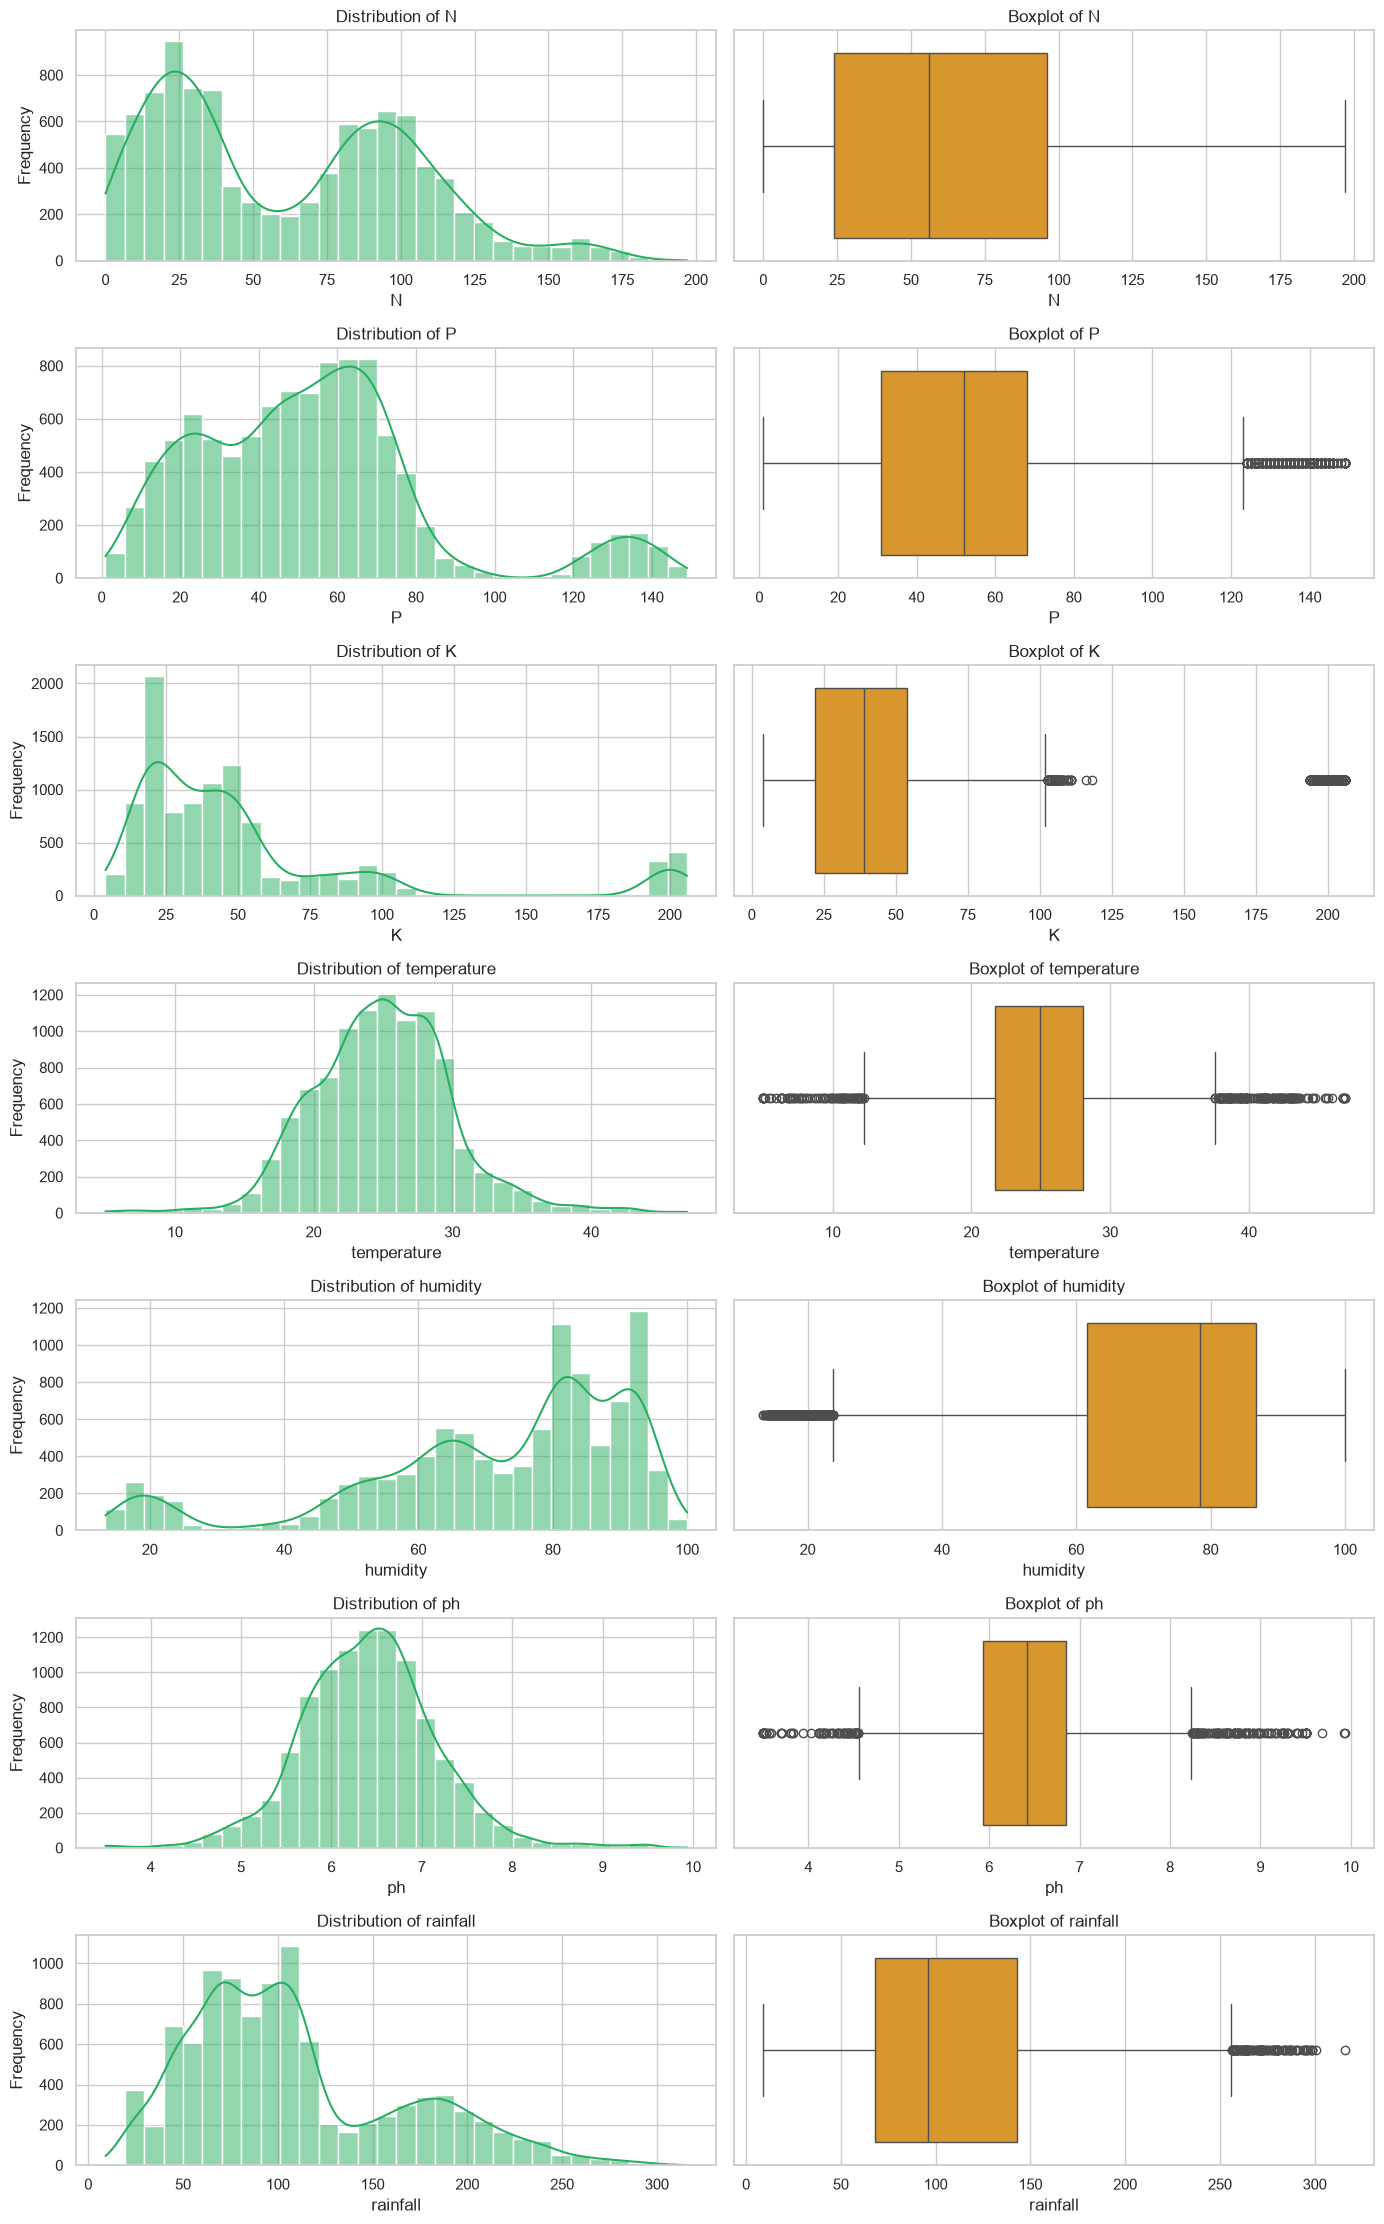

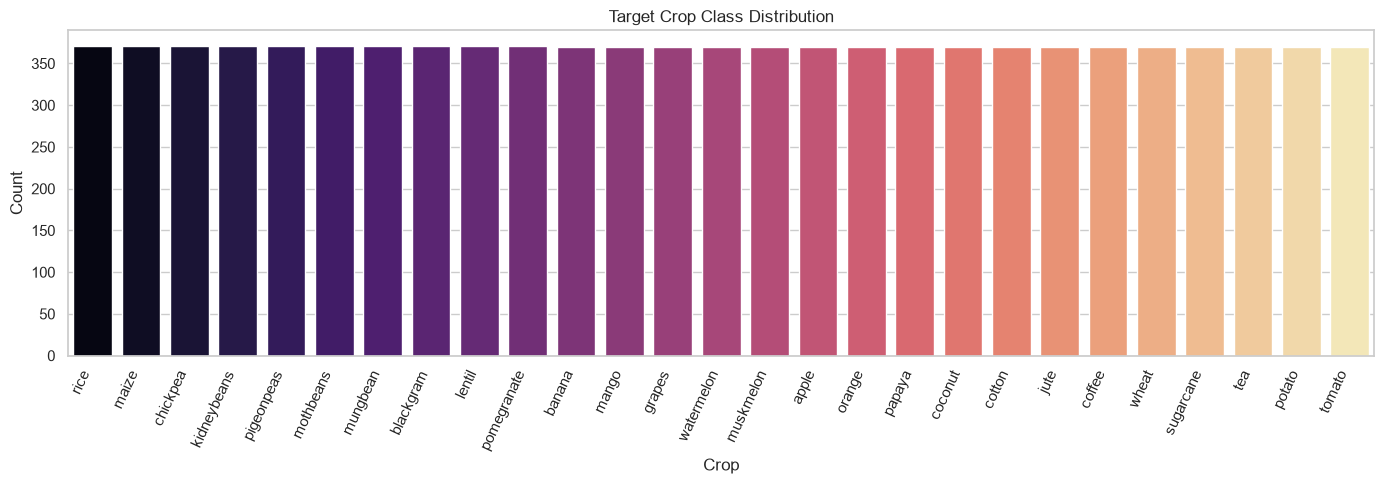

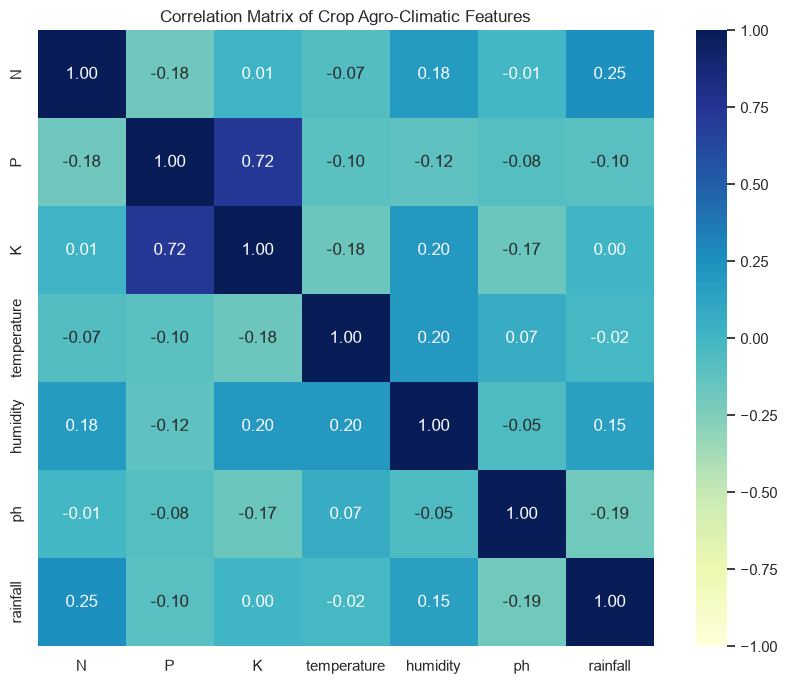

In [6]:
fig, axes = plt.subplots(nrows=len(crop_col_meta['numerical']), ncols=2, figsize=(14, 3.2 * len(crop_col_meta['numerical'])))
for idx, col in enumerate(crop_col_meta['numerical']):
    sns.histplot(crop_raw_df[col], kde=True, ax=axes[idx, 0], color='#27ae60', bins=30)
    axes[idx, 0].set_title(f"Distribution of {col}")
    axes[idx, 0].set_xlabel(col)
    axes[idx, 0].set_ylabel("Frequency")
    sns.boxplot(x=crop_raw_df[col], ax=axes[idx, 1], color='#f39c12')
    axes[idx, 1].set_title(f"Boxplot of {col}")
    axes[idx, 1].set_xlabel(col)
plt.tight_layout()
plt.show()

if crop_col_meta['target']:
    plt.figure(figsize=(14, 5))
    crop_counts = crop_raw_df[crop_col_meta['target']].value_counts()
    ax = sns.barplot(x=crop_counts.index, y=crop_counts.values, palette='magma')
    plt.title("Target Crop Class Distribution")
    plt.xlabel("Crop")
    plt.ylabel("Count")
    plt.xticks(rotation=65, ha='right')
    plt.tight_layout()
    plt.show()

plt.figure(figsize=(9, 7))
sns.heatmap(crop_raw_df[crop_col_meta['numerical']].corr(), annot=True, cmap='YlGnBu', fmt='.2f', vmin=-1, vmax=1, square=True)
plt.title("Correlation Matrix of Crop Agro-Climatic Features")
plt.tight_layout()
plt.show()

crop_cleaned_df = crop_raw_df.copy()
for col in crop_col_meta['categorical']:
    crop_cleaned_df[col] = crop_cleaned_df[col].astype(str).str.strip()
crop_cleaned_df = crop_cleaned_df.drop_duplicates().reset_index(drop=True)

crop_validation = pd.DataFrame({
    'Metric': ['Total Records', 'Total Columns', 'Missing Values', 'Exact Duplicates', 'Crop Classes'],
    'Raw Dataset': [
        len(crop_raw_df), 
        crop_raw_df.shape[1], 
        crop_raw_df.isnull().sum().sum(), 
        crop_duplicate_count,
        crop_raw_df[crop_col_meta['target']].nunique() if crop_col_meta['target'] else 'N/A'
    ],
    'Cleaned Dataset': [
        len(crop_cleaned_df), 
        crop_cleaned_df.shape[1], 
        crop_cleaned_df.isnull().sum().sum(), 
        crop_cleaned_df.duplicated().sum(),
        crop_cleaned_df[crop_col_meta['target']].nunique() if crop_col_meta['target'] else 'N/A'
    ]
})
display(crop_validation)

cleaned_crop_path = os.path.join(CROP_DIR, "crop_data_cleaned.csv")
report_crop_path = os.path.join(REPORT_DIR, "crop_preprocessing_report.csv")
crop_cleaned_df.to_csv(cleaned_crop_path, index=False)
crop_validation.to_csv(report_crop_path, index=False)


In [7]:
X_fert = fertilizer_cleaned_df.drop(columns=[fert_col_meta['target']])
y_fert = fertilizer_cleaned_df[fert_col_meta['target']]
fert_encoder = LabelEncoder()
y_fert_encoded = fert_encoder.fit_transform(y_fert)
X_fert_encoded = pd.get_dummies(X_fert, drop_first=True, dtype=int)
fert_feature_cols = X_fert_encoded.columns.tolist()

X_fert_train, X_fert_test, y_fert_train, y_fert_test = train_test_split(
    X_fert_encoded, y_fert_encoded, test_size=0.20, random_state=42, stratify=y_fert_encoded
)
num_cols_fert = fert_col_meta['numerical']
fert_scaler = StandardScaler()
X_fert_train_scaled = X_fert_train.copy()
X_fert_test_scaled = X_fert_test.copy()
X_fert_train_scaled[num_cols_fert] = fert_scaler.fit_transform(X_fert_train[num_cols_fert])
X_fert_test_scaled[num_cols_fert] = fert_scaler.transform(X_fert_test[num_cols_fert])

fert_classes = np.unique(y_fert_encoded)
fert_weights = compute_class_weight(class_weight='balanced', classes=fert_classes, y=y_fert_encoded)
fert_weight_dict = {fert_encoder.classes_[i]: round(float(fert_weights[i]), 4) for i in range(len(fert_classes))}

X_fert_train_scaled.to_csv(os.path.join(FERT_DIR, 'fertilizer_X_train.csv'), index=False)
X_fert_test_scaled.to_csv(os.path.join(FERT_DIR, 'fertilizer_X_test.csv'), index=False)
pd.Series(y_fert_train, name='target').to_csv(os.path.join(FERT_DIR, 'fertilizer_y_train.csv'), index=False)
pd.Series(y_fert_test, name='target').to_csv(os.path.join(FERT_DIR, 'fertilizer_y_test.csv'), index=False)
fert_mapping = {int(k): v for k, v in enumerate(fert_encoder.classes_)}
with open(os.path.join(FERT_DIR, 'fertilizer_class_mapping.json'), 'w') as f:
    json.dump(fert_mapping, f, indent=2)
with open(os.path.join(FERT_DIR, 'fertilizer_class_weights.json'), 'w') as f:
    json.dump(fert_weight_dict, f, indent=2)
with open(os.path.join(FERT_DIR, 'fertilizer_feature_columns.json'), 'w') as f:
    json.dump(fert_feature_cols, f, indent=2)
joblib.dump(fert_scaler, os.path.join(FERT_DIR, 'fertilizer_scaler.joblib'))
joblib.dump(fert_encoder, os.path.join(FERT_DIR, 'fertilizer_label_encoder.joblib'))

num_cols_crop = crop_col_meta['numerical']
X_crop = crop_cleaned_df[num_cols_crop]
y_crop = crop_cleaned_df[crop_col_meta['target']]
crop_encoder = LabelEncoder()
y_crop_encoded = crop_encoder.fit_transform(y_crop)
X_crop_train, X_crop_test, y_crop_train, y_crop_test = train_test_split(
    X_crop, y_crop_encoded, test_size=0.20, random_state=42, stratify=y_crop_encoded
)
crop_scaler = StandardScaler()
X_crop_train_scaled = pd.DataFrame(crop_scaler.fit_transform(X_crop_train), columns=num_cols_crop)
X_crop_test_scaled = pd.DataFrame(crop_scaler.transform(X_crop_test), columns=num_cols_crop)

crop_classes = np.unique(y_crop_encoded)
crop_weights = compute_class_weight(class_weight='balanced', classes=crop_classes, y=y_crop_encoded)
crop_weight_dict = {crop_encoder.classes_[i]: round(float(crop_weights[i]), 4) for i in range(len(crop_classes))}

X_crop_train_scaled.to_csv(os.path.join(CROP_DIR, 'crop_X_train.csv'), index=False)
X_crop_test_scaled.to_csv(os.path.join(CROP_DIR, 'crop_X_test.csv'), index=False)
pd.Series(y_crop_train, name='target').to_csv(os.path.join(CROP_DIR, 'crop_y_train.csv'), index=False)
pd.Series(y_crop_test, name='target').to_csv(os.path.join(CROP_DIR, 'crop_y_test.csv'), index=False)
crop_mapping = {int(k): v for k, v in enumerate(crop_encoder.classes_)}
with open(os.path.join(CROP_DIR, 'crop_class_mapping.json'), 'w') as f:
    json.dump(crop_mapping, f, indent=2)
with open(os.path.join(CROP_DIR, 'crop_class_weights.json'), 'w') as f:
    json.dump(crop_weight_dict, f, indent=2)
with open(os.path.join(CROP_DIR, 'crop_feature_columns.json'), 'w') as f:
    json.dump(num_cols_crop, f, indent=2)
joblib.dump(crop_scaler, os.path.join(CROP_DIR, 'crop_scaler.joblib'))
joblib.dump(crop_encoder, os.path.join(CROP_DIR, 'crop_label_encoder.joblib'))

ml_partition_summary = pd.DataFrame({
    'Subsystem': ['Fertilizer Recommendation', 'Crop Recommendation'],
    'Train Partition': [
        f'{X_fert_train_scaled.shape[0]:,} samples x {X_fert_train_scaled.shape[1]} features',
        f'{X_crop_train_scaled.shape[0]:,} samples x {X_crop_train_scaled.shape[1]} features'
    ],
    'Test Partition': [
        f'{X_fert_test_scaled.shape[0]:,} samples x {X_fert_test_scaled.shape[1]} features',
        f'{X_crop_test_scaled.shape[0]:,} samples x {X_crop_test_scaled.shape[1]} features'
    ],
    'Transformation Applied': [
        'One-Hot Encoded + StandardScaler + Class Weights',
        'StandardScaler + Class Weights'
    ],
    'Status': ['MODEL-READY', 'MODEL-READY']
})
display(ml_partition_summary)


                   Subsystem  ...       Status
0  Fertilizer Recommendation  ...  MODEL-READY
1        Crop Recommendation  ...  MODEL-READY

[2 rows x 5 columns]


In [8]:
loaded_fert_scaler = joblib.load(os.path.join(FERT_DIR, 'fertilizer_scaler.joblib'))
loaded_fert_encoder = joblib.load(os.path.join(FERT_DIR, 'fertilizer_label_encoder.joblib'))
with open(os.path.join(FERT_DIR, 'fertilizer_feature_columns.json')) as f:
    expected_fert_cols = json.load(f)

loaded_crop_scaler = joblib.load(os.path.join(CROP_DIR, 'crop_scaler.joblib'))
loaded_crop_encoder = joblib.load(os.path.join(CROP_DIR, 'crop_label_encoder.joblib'))
with open(os.path.join(CROP_DIR, 'crop_feature_columns.json')) as f:
    expected_crop_cols = json.load(f)

def transform_raw_fertilizer_input(raw_dict):
    df_single = pd.DataFrame([raw_dict])
    df_enc = pd.get_dummies(df_single, drop_first=True, dtype=int)
    for col in expected_fert_cols:
        if col not in df_enc.columns:
            df_enc[col] = 0
    df_enc = df_enc[expected_fert_cols]
    num_cols = fert_col_meta['numerical']
    df_enc[num_cols] = loaded_fert_scaler.transform(df_enc[num_cols])
    return df_enc

def transform_raw_crop_input(raw_dict):
    df_single = pd.DataFrame([raw_dict])[expected_crop_cols]
    return pd.DataFrame(loaded_crop_scaler.transform(df_single), columns=expected_crop_cols)

sample_fert_raw = fertilizer_raw_df.drop(columns=[fert_col_meta['target']]).iloc[0].to_dict()
sample_fert_transformed = transform_raw_fertilizer_input(sample_fert_raw)
assert sample_fert_transformed.shape[1] == len(expected_fert_cols)

sample_crop_raw = crop_raw_df.drop(columns=[crop_col_meta['target']]).iloc[0].to_dict()
sample_crop_transformed = transform_raw_crop_input(sample_crop_raw)
assert sample_crop_transformed.shape[1] == len(expected_crop_cols)

inference_test_summary = pd.DataFrame({
    'Pipeline': ['Fertilizer Inference Transformer', 'Crop Inference Transformer'],
    'Raw Input Features': [len(sample_fert_raw), len(sample_crop_raw)],
    'Transformed Vector Dimension': [sample_fert_transformed.shape[1], sample_crop_transformed.shape[1]],
    'Pipeline Status': ['VERIFIED / BACKEND-READY', 'VERIFIED / BACKEND-READY']
})
display(inference_test_summary)


                           Pipeline  ...           Pipeline Status
0  Fertilizer Inference Transformer  ...  VERIFIED / BACKEND-READY
1        Crop Inference Transformer  ...  VERIFIED / BACKEND-READY

[2 rows x 4 columns]


                     Dataset  ...                 Quality Status
0  Fertilizer Recommendation  ...  VERIFIED / READY FOR MODELING
1        Crop Recommendation  ...  VERIFIED / READY FOR MODELING

[2 rows x 10 columns]
All ML Data Preprocessing Assertions Passed (100% Integrity)

Fertilizer Preprocessed Directory (10 files):
  * fertilizer_X_test.csv               :   272.90 KB
  * fertilizer_X_train.csv              :  1089.99 KB
  * fertilizer_class_mapping.json       :     0.12 KB
  * fertilizer_class_weights.json       :     0.14 KB
  * fertilizer_data_cleaned.csv         :   514.56 KB
  * fertilizer_feature_columns.json     :     0.77 KB
  * fertilizer_label_encoder.joblib     :     0.52 KB
  * fertilizer_scaler.joblib            :     0.94 KB
  * fertilizer_y_test.csv               :     5.87 KB
  * fertilizer_y_train.csv              :    23.45 KB

Crop Preprocessed Directory (10 files):
  * crop_X_test.csv                     :   270.90 KB
  * crop_X_train.csv                   

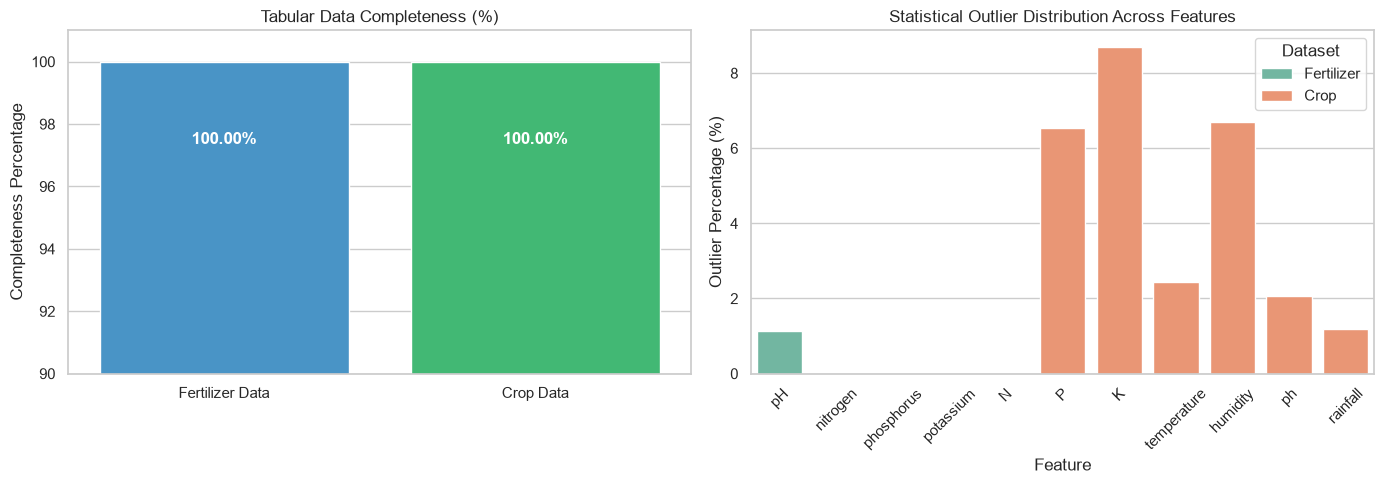

In [9]:
ml_consolidated_records = [
    {
        'Dataset': 'Fertilizer Recommendation',
        'Data Modality': 'Tabular (Laboratory Soil Tests)',
        'Initial Count': f"{len(fertilizer_raw_df):,} rows",
        'Cleaned Count': f"{len(fertilizer_cleaned_df):,} rows",
        'Features': fertilizer_cleaned_df.shape[1],
        'Missing (Before -> After)': f"{fertilizer_raw_df.isnull().sum().sum()} -> {fertilizer_cleaned_df.isnull().sum().sum()}",
        'Duplicates (Before -> After)': f"{fert_duplicate_count} -> {fertilizer_cleaned_df.duplicated().sum()}",
        'Invalid/Corrupt Items': 0,
        'Target Identified': fert_col_meta['target'],
        'Quality Status': 'VERIFIED / READY FOR MODELING'
    },
    {
        'Dataset': 'Crop Recommendation',
        'Data Modality': 'Tabular (Agro-Climatic Measurements)',
        'Initial Count': f"{len(crop_raw_df):,} rows",
        'Cleaned Count': f"{len(crop_cleaned_df):,} rows",
        'Features': crop_cleaned_df.shape[1],
        'Missing (Before -> After)': f"{crop_raw_df.isnull().sum().sum()} -> {crop_cleaned_df.isnull().sum().sum()}",
        'Duplicates (Before -> After)': f"{crop_duplicate_count} -> {crop_cleaned_df.duplicated().sum()}",
        'Invalid/Corrupt Items': 0,
        'Target Identified': crop_col_meta['target'],
        'Quality Status': 'VERIFIED / READY FOR MODELING'
    }
]

ml_summary_df = pd.DataFrame(ml_consolidated_records)
display(ml_summary_df)
ml_summary_path = os.path.join(REPORT_DIR, "ml_preprocessing_summary.csv")
ml_summary_df.to_csv(ml_summary_path, index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
datasets = ['Fertilizer Data', 'Crop Data']
completeness = [
    (1 - fertilizer_cleaned_df.isnull().sum().sum() / fertilizer_cleaned_df.size) * 100,
    (1 - crop_cleaned_df.isnull().sum().sum() / crop_cleaned_df.size) * 100
]
sns.barplot(x=datasets, y=completeness, ax=axes[0], palette=['#3498db', '#2ecc71'])
axes[0].set_ylim(90, 101)
axes[0].set_title("Tabular Data Completeness (%)")
axes[0].set_ylabel("Completeness Percentage")
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height() - 2.5),
                     ha='center', va='center', color='white', fontweight='bold')

outlier_comp = pd.concat([
    fert_outlier_df[['Feature', 'Outlier Percentage (%)']].assign(Dataset='Fertilizer'),
    crop_outlier_df[['Feature', 'Outlier Percentage (%)']].assign(Dataset='Crop')
])
sns.barplot(data=outlier_comp, x='Feature', y='Outlier Percentage (%)', hue='Dataset', ax=axes[1], palette='Set2')
axes[1].set_title("Statistical Outlier Distribution Across Features")
axes[1].tick_params(axis='x', rotation=45)
axes[1].set_ylabel("Outlier Percentage (%)")
plt.tight_layout()
plt.show()

reloaded_fert = pd.read_csv(cleaned_fert_path)
reloaded_crop = pd.read_csv(cleaned_crop_path)
reloaded_fert_xtrain = pd.read_csv(os.path.join(FERT_DIR, 'fertilizer_X_train.csv'))
reloaded_crop_xtrain = pd.read_csv(os.path.join(CROP_DIR, 'crop_X_train.csv'))

assert len(reloaded_fert) == len(fertilizer_cleaned_df)
assert len(reloaded_crop) == len(crop_cleaned_df)
assert reloaded_fert.isnull().sum().sum() == 0
assert reloaded_crop.isnull().sum().sum() == 0
assert len(reloaded_fert_xtrain) == 8000
assert len(reloaded_crop_xtrain) == 8000

print("All ML Data Preprocessing Assertions Passed (100% Integrity)")

organized_dirs = {
    'Fertilizer Preprocessed Directory': FERT_DIR,
    'Crop Preprocessed Directory': CROP_DIR,
    'ML Reports Directory': REPORT_DIR
}

for desc, dpath in organized_dirs.items():
    files = [f for f in os.listdir(dpath) if os.path.isfile(os.path.join(dpath, f))]
    print(f"\n{desc} ({len(files)} files):")
    for f in sorted(files):
        sz_kb = os.path.getsize(os.path.join(dpath, f)) / 1024
        print(f"  * {f:<35} : {sz_kb:>8.2f} KB")

print("\nMACHINE LEARNING DATA PREPROCESSING COMPLETE & VERIFIED")
